# Pair-trading equations: mathematical and strategy validation

This notebook audits the supplied equation sheet against `teamName.py` and `prices.txt`. It distinguishes algebraic identities (which can be proved), statistical evidence (which cannot prove cointegration), and realised strategy attribution (which is not judged only by the competition score). All causal estimates use information available before the observation being scored.

## Audit of the supplied equations

| Claim | Verdict | Important qualification |
|---|---|---|
| $y_t=\alpha+\beta x_t+\epsilon_t$ and OLS normal equations | Correct | The strategy fits **log prices**. Numerically use `lstsq`/centred OLS rather than an explicit inverse. |
| Spread $\epsilon_t=y_t-\alpha-\beta x_t$ | Correct | With an OLS intercept, the in-sample residual already has mean zero. Demeaning it again is redundant. |
| Trade signed spread z-score | Correct in principle | A high cointegration **p-value is weak evidence**, not moneyness. The current generic detector uses an expanding residual z-score, not a rolling p-value. |
| $n_x=-\beta n_y$ | Incorrect for this strategy | For a log-price regression, $\beta$ maps **dollar exposures**. Correct shares satisfy $n_x=-\beta n_y P_y/P_x$. |
| $\Delta PnL=n_y(\Delta y-\beta\Delta x)$ | Only for a raw-price regression | For log prices, $\Delta PnL\approx D_y(\Delta\log P_y-\beta\Delta\log P_x)$. |
| Kalman innovation z-score | Equations mostly correct | It must be $e_t/\sqrt{S_t}$, not $e_t/S_t$. The atlas implementation uses a Kalman beta but a separate 145-day spread z-score. |
| Market beta regressions on price levels | Incorrect | Estimate market beta on returns. Price-level regressions can be spurious. |
| Residual beta from $\Delta\epsilon_t$ | Correct for a fixed log hedge | Regress $r_y-\beta r_x$ on the market return. Regressing a stationary residual level on a non-stationary market level is generally invalid. |
| Half-life $-\log 2/\log\phi$ | Correct for $0<\phi<1$ | A fitted value is an estimate conditional on an AR(1) approximation, not proof of future reversion. |
| Engle–Granger residual ADF | Correct framework | `rho < 0` alone is insufficient; use Engle–Granger/MacKinnon critical values or p-values. |
| Gregory–Hansen break equation | Meaningful model | The equation alone is not the test; unknown-break search requires non-standard critical values. We show only a descriptive break fit below. |

In [1]:
from pathlib import Path
from collections import Counter
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats
from statsmodels.tsa.stattools import adfuller, coint

from benchmark_teamname import load_strategy

warnings.filterwarnings('ignore', category=RuntimeWarning)
plt.style.use('seaborn-v0_8-whitegrid')
OUT = Path('cointegration_output/pair_equation_validation')
OUT.mkdir(parents=True, exist_ok=True)

prices_df = pd.read_csv('prices.txt', sep=r'\s+')
names = prices_df.columns.to_list()
prices = prices_df.to_numpy(float).T
logp = np.log(prices)
name_to_i = {name: i for i, name in enumerate(names)}
strategy = load_strategy('teamName')

print(f'{len(names)} instruments, {prices.shape[1]} days')
print('Current source parameters:', {
    'RIDGE_ENTRY': strategy.RIDGE_ENTRY,
    'PAIR_MIN_HISTORY': strategy.PAIR_MIN_HISTORY,
    'PAIR_ENTRY_Z': strategy.PAIR_ENTRY_Z,
    'PAIR_SCALE': strategy.PAIR_SCALE,
})

51 instruments, 750 days
Current source parameters: {'RIDGE_ENTRY': 0.75, 'PAIR_MIN_HISTORY': 120, 'PAIR_ENTRY_Z': 2.0, 'PAIR_SCALE': 1}


In [2]:
def ols_fit(y, x):
    xc = x - x.mean()
    yc = y - y.mean()
    beta = float(xc @ yc / max(xc @ xc, 1e-18))
    alpha = float(y.mean() - beta * x.mean())
    residual = y - alpha - beta * x
    return alpha, beta, residual

def ar1_half_life(residual):
    lag, target = residual[:-1], residual[1:]
    _, phi, _ = ols_fit(target, lag)
    if not 0.0 < phi < 1.0:
        return np.inf, phi
    return float(-np.log(2.0) / np.log(phi)), phi

def slope(y, x):
    xc, yc = x - x.mean(), y - y.mean()
    return float(xc @ yc / max(xc @ xc, 1e-18))

def fixed_pair_metrics(i, j, split=500):
    y0, x0 = logp[i, :split], logp[j, :split]
    alpha, beta, train_resid = ols_fit(y0, x0)
    test_resid = logp[i, split:] - alpha - beta * logp[j, split:]
    _, beta_test, _ = ols_fit(logp[i, split:], logp[j, split:])
    hl_train, phi_train = ar1_half_life(train_resid)
    hl_test, phi_test = ar1_half_life(test_resid)
    train_coint_p = coint(y0, x0, trend='c', maxlag=1, autolag=None)[1]
    test_coint_p = coint(logp[i, split:], logp[j, split:], trend='c', maxlag=1, autolag=None)[1]
    market = np.diff(logp[0])
    spread_return = np.diff(logp[i] - beta * logp[j])
    resid_market_beta = slope(spread_return, market)
    orth_mean = abs(train_resid.mean())
    orth_x = abs((x0 - x0.mean()) @ train_resid) / max(len(x0), 1)
    return {
        'pair': f'{names[i]}~{names[j]}', 'alpha': alpha, 'beta_train': beta,
        'beta_test': beta_test, 'beta_change_pct': 100 * (beta_test / beta - 1),
        'EG_p_train': train_coint_p, 'EG_p_test_refit': test_coint_p,
        'half_life_train': hl_train, 'half_life_test_fixed': hl_test,
        'phi_train': phi_train, 'phi_test': phi_test,
        'residual_market_beta': resid_market_beta,
        'OLS_mean_residual_abs': orth_mean, 'OLS_x_residual_dot_per_obs': orth_x,
    }

def causal_z_path(i, j, minimum=120):
    z = np.full(prices.shape[1], np.nan)
    beta_path = np.full(prices.shape[1], np.nan)
    for t in range(minimum, prices.shape[1]):
        alpha, beta, residual = ols_fit(logp[i, :t], logp[j, :t])
        current = logp[i, t] - alpha - beta * logp[j, t]
        z[t] = current / (residual.std() + 1e-12)
        beta_path[t] = beta
    return z, beta_path

def causal_reversion(i, j, horizon=5, minimum=120, threshold=2.0):
    outcomes = []
    for t in range(minimum, prices.shape[1] - horizon):
        alpha, beta, residual = ols_fit(logp[i, :t], logp[j, :t])
        current = logp[i, t] - alpha - beta * logp[j, t]
        z = current / (residual.std() + 1e-12)
        if abs(z) < threshold:
            continue
        future_change = ((logp[i, t + horizon] - beta * logp[j, t + horizon])
                         - (logp[i, t] - beta * logp[j, t]))
        outcomes.append(-np.sign(z) * future_change * 1e4)
    outcomes = np.asarray(outcomes)
    return {
        f'n_h{horizon}': len(outcomes),
        f'mean_bps_h{horizon}': outcomes.mean() if len(outcomes) else np.nan,
        f'median_bps_h{horizon}': np.median(outcomes) if len(outcomes) else np.nan,
        f'win_rate_h{horizon}': np.mean(outcomes > 0) if len(outcomes) else np.nan,
    }

## Relationship evidence and OLS identities

The document mentions SMAH and NGTE, but that is not one of the fixed atlas pairs. We compare it with the actual SMAH–ILVX and EORC–NGTE atlas relationships. Engle–Granger p-values are evidence against a unit root, not mathematical proof. The last two columns numerically verify the exact OLS orthogonality conditions.

In [3]:
document_pair = (name_to_i['SMAH'], name_to_i['NGTE'])
atlas_examples = [
    (name_to_i['SMAH'], name_to_i['ILVX']),
    (name_to_i['EORC'], name_to_i['NGTE']),
]
initial_pairs = [document_pair] + atlas_examples
rows = []
for i, j in initial_pairs:
    row = fixed_pair_metrics(i, j)
    row.update(causal_reversion(i, j, horizon=5))
    row.update(causal_reversion(i, j, horizon=20))
    rows.append(row)
pair_table = pd.DataFrame(rows)
display(pair_table.round(5))
assert pair_table['OLS_mean_residual_abs'].max() < 1e-10
assert pair_table['OLS_x_residual_dot_per_obs'].max() < 1e-10
print('OLS normal-equation identities verified to numerical precision.')

,pair,alpha,beta_train,beta_test,beta_change_pct,EG_p_train,EG_p_test_refit,half_life_train,half_life_test_fixed,phi_train,...,OLS_mean_residual_abs,OLS_x_residual_dot_per_obs,n_h5,mean_bps_h5,median_bps_h5,win_rate_h5,n_h20,mean_bps_h20,median_bps_h20,win_rate_h20
0,SMAH~NGTE,3.18571,0.21411,0.67428,214.91443,0.80167,0.00082,110.91149,12.10277,0.99377,...,0.0,0.0,133,-67.42049,-120.13998,0.42105,133,-308.66235,-151.45970,0.42857
1,SMAH~ILVX,0.19265,1.03107,0.98067,-4.88823,0.00000,0.00082,4.84442,4.86362,0.86668,...,0.0,0.0,51,460.24061,427.24089,0.80392,51,589.67460,565.19764,0.94118
2,EORC~NGTE,-0.55481,1.01121,0.91402,-9.61151,0.00003,0.00244,5.10188,4.05905,0.87296,...,0.0,0.0,61,387.62593,398.20889,0.77049,61,674.40798,646.66126,0.93443


OLS normal-equation identities verified to numerical precision.


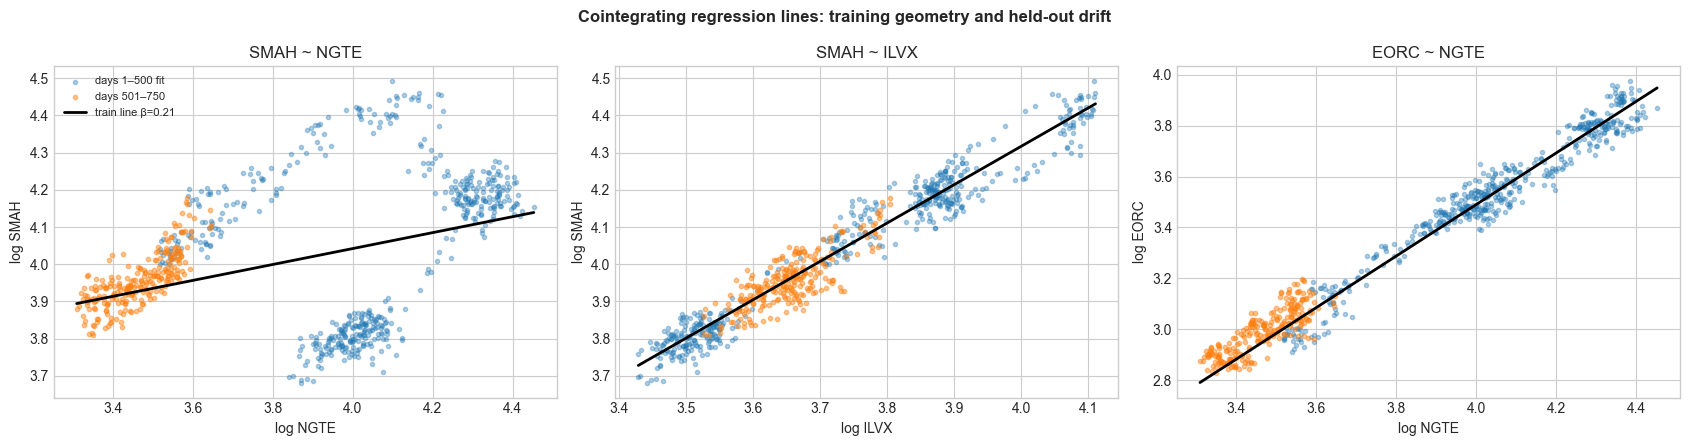

In [4]:
fig, axes = plt.subplots(1, len(initial_pairs), figsize=(17, 4.5))
for ax, (i, j) in zip(axes, initial_pairs):
    alpha, beta, _ = ols_fit(logp[i, :500], logp[j, :500])
    ax.scatter(logp[j, :500], logp[i, :500], s=9, alpha=.35, label='days 1–500 fit')
    ax.scatter(logp[j, 500:], logp[i, 500:], s=10, alpha=.45, label='days 501–750')
    xx = np.linspace(logp[j].min(), logp[j].max(), 100)
    ax.plot(xx, alpha + beta * xx, color='black', lw=2, label=f'train line β={beta:.2f}')
    ax.set(title=f'{names[i]} ~ {names[j]}', xlabel=f'log {names[j]}', ylabel=f'log {names[i]}')
axes[0].legend(fontsize=8)
fig.suptitle('Cointegrating regression lines: training geometry and held-out drift', fontweight='bold')
fig.tight_layout()
fig.savefig(OUT / 'regression_lines.png', dpi=160, bbox_inches='tight')
plt.show()

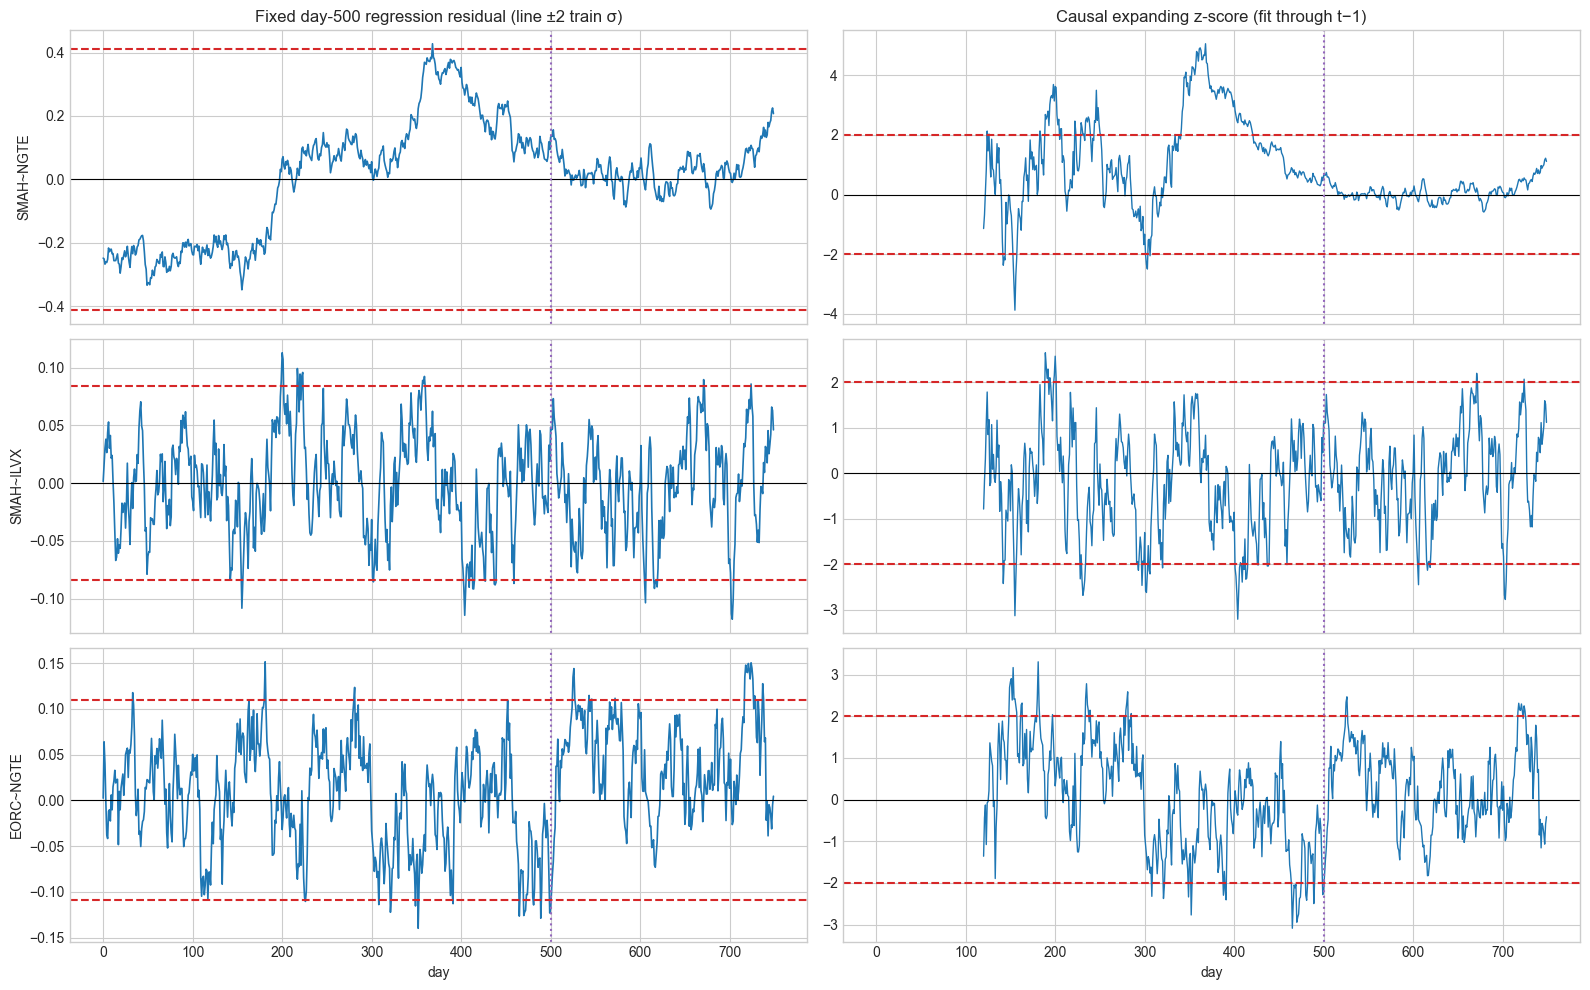

In [5]:
fig, axes = plt.subplots(len(initial_pairs), 2, figsize=(16, 10), sharex=True)
for row, (i, j) in enumerate(initial_pairs):
    alpha, beta, train_resid = ols_fit(logp[i, :500], logp[j, :500])
    residual = logp[i] - alpha - beta * logp[j]
    sigma = train_resid.std()
    axes[row, 0].plot(residual, lw=1.2)
    axes[row, 0].axhline(0, color='black', lw=.8)
    axes[row, 0].axhline(2*sigma, color='tab:red', ls='--')
    axes[row, 0].axhline(-2*sigma, color='tab:red', ls='--')
    axes[row, 0].axvline(500, color='tab:purple', ls=':', lw=1.5)
    axes[row, 0].set_ylabel(f'{names[i]}~{names[j]}')
    z, _ = causal_z_path(i, j)
    axes[row, 1].plot(z, lw=1.0, color='tab:blue')
    axes[row, 1].axhline(2, color='tab:red', ls='--')
    axes[row, 1].axhline(-2, color='tab:red', ls='--')
    axes[row, 1].axhline(0, color='black', lw=.8)
    axes[row, 1].axvline(500, color='tab:purple', ls=':', lw=1.5)
axes[0, 0].set_title('Fixed day-500 regression residual (line ±2 train σ)')
axes[0, 1].set_title('Causal expanding z-score (fit through t−1)')
axes[-1, 0].set_xlabel('day')
axes[-1, 1].set_xlabel('day')
fig.tight_layout()
fig.savefig(OUT / 'spreads_and_causal_scores.png', dpi=160, bbox_inches='tight')
plt.show()

## Atlas-wide stability and structural breaks

The next table applies the same day-500 fixed-fit test to every atlas pair. A descriptive one-break regression can show that two lines fit much better than one; it is not a Gregory–Hansen significance test because the break date was searched and the critical values are non-standard.

In [6]:
atlas_pairs = list(strategy.ATLAS_PAIRS)
atlas_metrics = pd.DataFrame([fixed_pair_metrics(i, j) for i, j in atlas_pairs])
display(atlas_metrics.sort_values('EG_p_test_refit').round(5))
print('Train EG p<5%:', int((atlas_metrics.EG_p_train < .05).sum()), '/', len(atlas_metrics))
print('Held-out refit EG p<5%:', int((atlas_metrics.EG_p_test_refit < .05).sum()), '/', len(atlas_metrics))
print('Median absolute beta change:', f"{atlas_metrics.beta_change_pct.abs().median():.1f}%")

,pair,alpha,beta_train,beta_test,beta_change_pct,EG_p_train,EG_p_test_refit,half_life_train,half_life_test_fixed,phi_train,phi_test,residual_market_beta,OLS_mean_residual_abs,OLS_x_residual_dot_per_obs
0,SMAH~ILVX,0.19265,1.03107,0.98067,-4.88823,0.00000,0.00082,4.84442,4.86362,0.86668,0.86717,0.09234,0.0,0.0
2,EORC~NGTE,-0.55481,1.01121,0.91402,-9.61151,0.00003,0.00244,5.10188,4.05905,0.87296,0.84302,-0.10788,0.0,0.0
3,HUXZ~ACAC,0.01760,1.02014,0.99205,-2.75358,0.00006,0.00287,5.62483,3.65172,0.88406,0.82711,0.04145,0.0,0.0
5,MHRM~EAFC,-0.47931,0.94104,0.92925,-1.25193,0.00023,0.00792,6.38593,4.42005,0.89714,0.85486,-0.01529,0.0,0.0
8,FWWG~BLBT,0.02952,0.91187,0.87612,-3.92032,0.00492,0.00817,9.27633,7.11799,0.92800,0.90721,0.15561,0.0,0.0
1,AENO~NWIG,0.01851,0.98160,0.79336,-19.17709,0.00000,0.00881,3.72282,6.07243,0.83012,0.89213,-0.01485,0.0,0.0
6,HETT~ULXY,1.42740,0.70722,0.86281,22.00016,0.00030,0.03535,7.26770,9.38342,0.90903,0.92879,-0.04687,0.0,0.0
9,RTTH~NAYO,0.60864,0.84539,0.80672,-4.57364,0.00135,0.07343,9.80730,6.54505,0.93176,0.89951,-0.06135,0.0,0.0
4,CTGI~EELT,0.33279,0.93333,0.90180,-3.37827,0.00012,0.09182,6.50571,7.81049,0.89894,0.91508,-0.11612,0.0,0.0
11,NAYO~SRTX,1.04908,0.43594,-0.71430,-263.85389,0.00282,0.14035,9.71616,47.15405,0.93115,0.98541,0.91082,0.0,0.0


Train EG p<5%: 13 / 13
Held-out refit EG p<5%: 7 / 13
Median absolute beta change: 9.6%


,pair,break_day,BIC_improvement,alpha_pre,beta_pre,alpha_post,beta_post,i,j
9,RTTH~NAYO,102,314.4245,2.2438,0.4244,1.3457,0.6237,18,35
5,MHRM~EAFC,298,219.5208,0.8263,0.5797,-1.0837,1.1278,49,50
1,AENO~NWIG,236,176.2752,1.4517,0.6858,0.1768,0.9433,1,20
12,ALUT~CCNS,135,171.5657,0.5155,0.7642,1.0515,0.5590,26,32
4,CTGI~EELT,195,167.0514,2.9525,0.3421,1.2823,0.7368,25,37
8,FWWG~BLBT,318,140.7586,1.3118,0.5795,0.5018,0.7778,36,41
7,ACIX~ITPA,399,139.8437,-0.1290,0.9854,0.2920,0.8351,31,43
0,SMAH~ILVX,399,89.2012,0.0673,1.0663,1.1474,0.7775,10,46


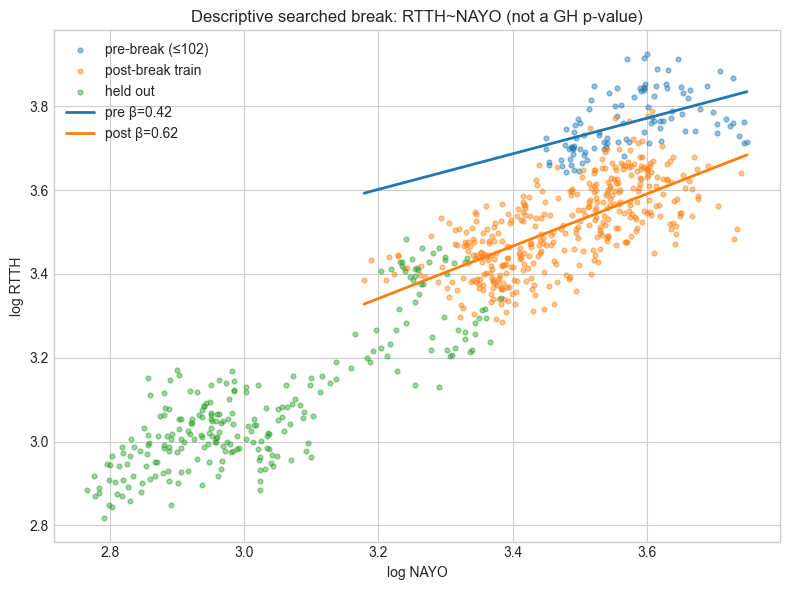

In [7]:
def best_descriptive_break(i, j, end=500):
    y, x = logp[i, :end], logp[j, :end]
    a0, b0, r0 = ols_fit(y, x)
    base_bic = end * np.log(np.mean(r0*r0)) + 2*np.log(end)
    best = None
    for cut in range(100, end-99):
        a1, b1, r1 = ols_fit(y[:cut], x[:cut])
        a2, b2, r2 = ols_fit(y[cut:], x[cut:])
        rss = r1@r1 + r2@r2
        bic = end*np.log(rss/end) + 4*np.log(end)
        candidate = (bic, cut, a1, b1, a2, b2)
        if best is None or candidate[0] < best[0]:
            best = candidate
    bic, cut, a1, b1, a2, b2 = best
    return {'pair': f'{names[i]}~{names[j]}', 'break_day': cut,
            'BIC_improvement': base_bic-bic, 'alpha_pre': a1, 'beta_pre': b1,
            'alpha_post': a2, 'beta_post': b2, 'i': i, 'j': j}

breaks = pd.DataFrame([best_descriptive_break(i, j) for i, j in atlas_pairs])
display(breaks.sort_values('BIC_improvement', ascending=False).head(8).round(4))
winner = breaks.sort_values('BIC_improvement', ascending=False).iloc[0]
i, j, cut = int(winner.i), int(winner.j), int(winner.break_day)
fig, ax = plt.subplots(figsize=(8, 6))
ax.scatter(logp[j, :cut], logp[i, :cut], s=12, alpha=.45, label=f'pre-break (≤{cut})')
ax.scatter(logp[j, cut:500], logp[i, cut:500], s=12, alpha=.45, label='post-break train')
ax.scatter(logp[j, 500:], logp[i, 500:], s=12, alpha=.45, label='held out')
xx = np.linspace(logp[j, :500].min(), logp[j, :500].max(), 100)
ax.plot(xx, winner.alpha_pre + winner.beta_pre*xx, lw=2, label=f'pre β={winner.beta_pre:.2f}')
ax.plot(xx, winner.alpha_post + winner.beta_post*xx, lw=2, label=f'post β={winner.beta_post:.2f}')
ax.set(title=f'Descriptive searched break: {winner.pair} (not a GH p-value)',
       xlabel=f'log {names[j]}', ylabel=f'log {names[i]}')
ax.legend()
fig.tight_layout()
fig.savefig(OUT / 'descriptive_structural_break.png', dpi=160, bbox_inches='tight')
plt.show()

## Kalman equations versus the atlas implementation

A proper innovation score uses the prediction made before observing day $t$ and divides by $\sqrt{S_t}$. The plots below show that causal innovation and the time-varying beta. `teamName.py` uses this Kalman machinery for the atlas beta, but its entry score is separately normalised over the last 145 fixed-beta spread observations.

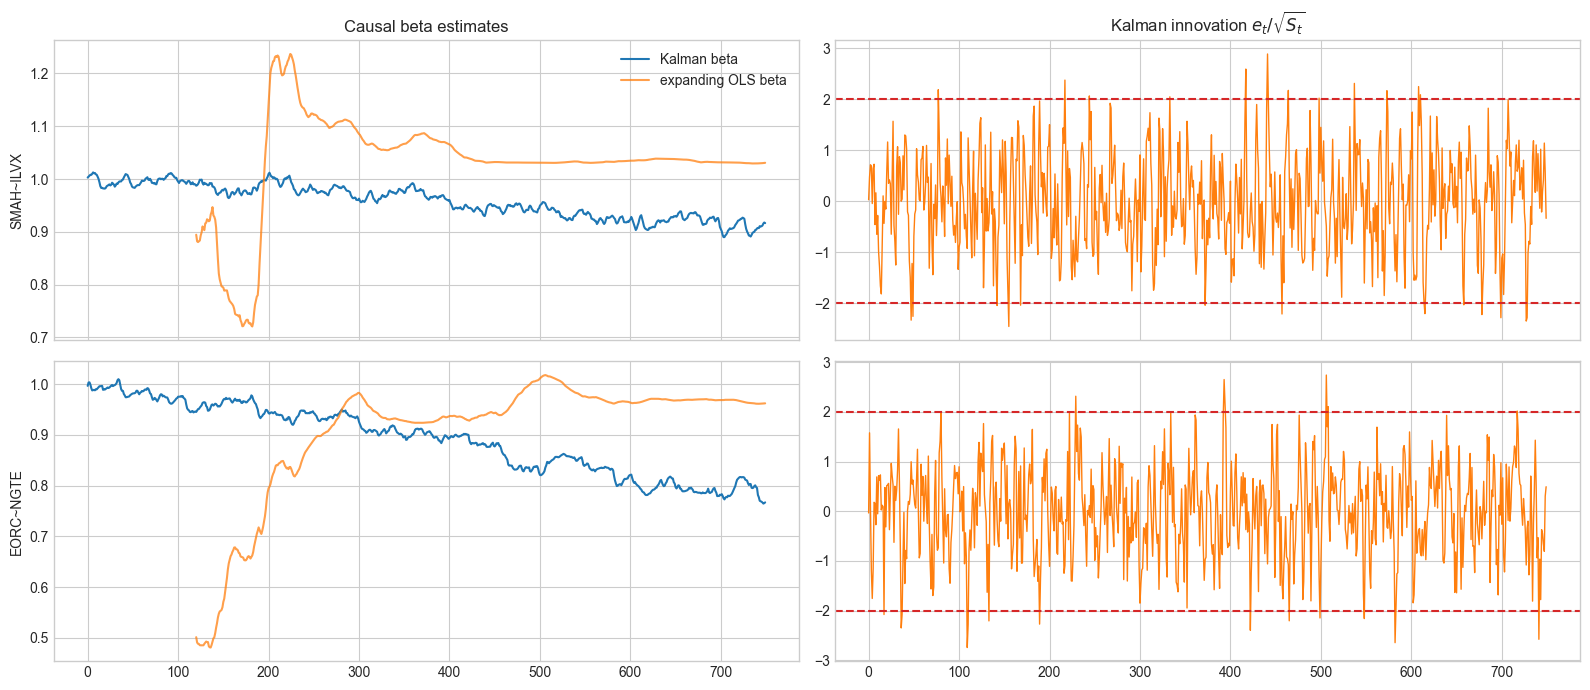

In [8]:
def kalman_path(y, x):
    theta = np.array([y[:60].mean()-x[:60].mean(), 1.0])
    P = np.eye(2)*1e-2
    Q = np.eye(2)*1e-5
    R = np.var(np.diff(y[:120]-x[:120])) + 1e-8
    beta, innovation_z = np.full(len(y), np.nan), np.full(len(y), np.nan)
    for t in range(len(y)):
        P_pred = P + Q
        H = np.array([1.0, x[t]])
        error = y[t] - H@theta
        S = H@P_pred@H + R
        innovation_z[t] = error/np.sqrt(S)
        K = P_pred@H/S
        theta = theta + K*error
        P = P_pred - np.outer(K, H)@P_pred
        beta[t] = theta[1]
    return beta, innovation_z

fig, axes = plt.subplots(len(atlas_examples), 2, figsize=(16, 7), sharex=True)
for row, (i, j) in enumerate(atlas_examples):
    kb, kz = kalman_path(logp[i], logp[j])
    _, ob = causal_z_path(i, j)
    axes[row, 0].plot(kb, label='Kalman beta')
    axes[row, 0].plot(ob, alpha=.75, label='expanding OLS beta')
    axes[row, 0].set_ylabel(f'{names[i]}~{names[j]}')
    axes[row, 1].plot(kz, color='tab:orange', lw=1)
    axes[row, 1].axhline(2, color='tab:red', ls='--')
    axes[row, 1].axhline(-2, color='tab:red', ls='--')
axes[0, 0].set_title('Causal beta estimates')
axes[0, 1].set_title(r'Kalman innovation $e_t/\sqrt{S_t}$')
axes[0, 0].legend()
fig.tight_layout()
fig.savefig(OUT / 'kalman_beta_and_innovation.png', dpi=160, bbox_inches='tight')
plt.show()

## Spread hedge ratio is not market beta

For log returns, the spread return is $r_y-\beta_{spread}r_x$. If each asset has ALGO beta $b_y,b_x$, its residual market beta is $b_y-\beta_{spread}b_x$. Equal-dollar atlas execution instead has beta $b_y-b_x$. Neither construction guarantees zero market beta; explicit market neutrality would use a different leg ratio.

,pair,spread_beta,asset_beta_y,asset_beta_x,market_beta_equal_dollar,market_beta_spread_weighted,market_neutral_x_dollar_per_y
0,SMAH~NGTE,0.2141,0.9711,1.0898,-0.1187,0.7377,-0.8910
1,SMAH~ILVX,1.0311,0.9711,0.8200,0.1511,0.1256,-1.1842
2,EORC~NGTE,1.0112,0.9430,1.0898,-0.1468,-0.1590,-0.8653


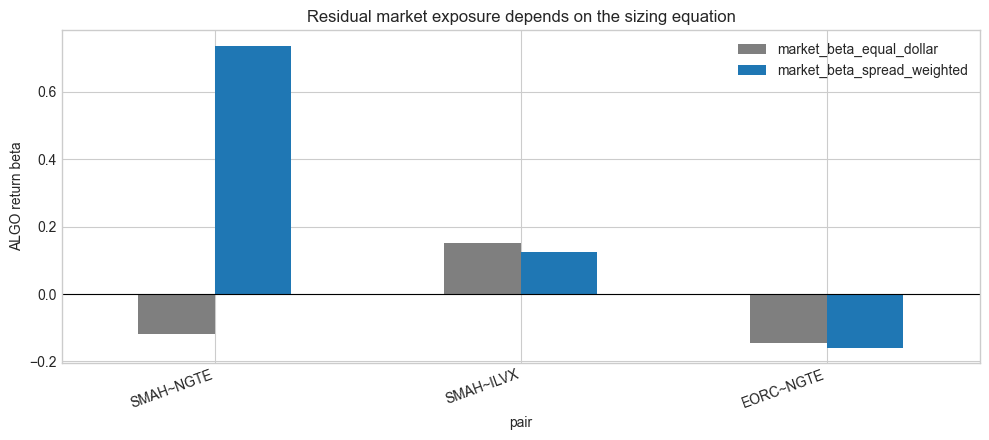

In [9]:
market_r = np.diff(logp[0, :500])
beta_rows = []
for i, j in initial_pairs:
    _, spread_beta, _ = ols_fit(logp[i, :500], logp[j, :500])
    by = slope(np.diff(logp[i, :500]), market_r)
    bx = slope(np.diff(logp[j, :500]), market_r)
    beta_rows.append({
        'pair': f'{names[i]}~{names[j]}', 'spread_beta': spread_beta,
        'asset_beta_y': by, 'asset_beta_x': bx,
        'market_beta_equal_dollar': by-bx,
        'market_beta_spread_weighted': by-spread_beta*bx,
        'market_neutral_x_dollar_per_y': -by/bx if abs(bx)>1e-12 else np.nan,
    })
beta_table = pd.DataFrame(beta_rows)
display(beta_table.round(4))
ax = beta_table.set_index('pair')[['market_beta_equal_dollar','market_beta_spread_weighted']].plot.bar(
    figsize=(10, 4.5), color=['tab:gray','tab:blue'])
ax.axhline(0, color='black', lw=.8)
ax.set(ylabel='ALGO return beta', title='Residual market exposure depends on the sizing equation')
plt.xticks(rotation=20, ha='right')
plt.tight_layout()
plt.savefig(OUT / 'residual_market_beta.png', dpi=160, bbox_inches='tight')
plt.show()

## Pair-sleeve attribution inside the current strategy

This is not another competition-score comparison. We isolate the raw atlas sleeve and the actual expanding-discovery overlay on days 501–750, include one-basis-point turnover cost, report a HAC t-statistic for mean daily PnL, ALGO beta of gross-normalised returns, drawdown, and the error in the log-PnL approximation. Statistical significance is evidence, not proof of a future edge.

,sleeve,days_active,mean_daily_pnl,pnl_std,annualised_sharpe,HAC_t_mean,cumulative_pnl,hit_rate,max_drawdown,mean_gross_active,ALGO_beta_gross_return,log_PnL_RMSE
0,atlas,250,370.3842,784.3759,7.4662,8.1561,92596.0399,0.672,-3505.6463,177400.0000,-0.0092,16.0572
1,expanding discovery,248,2.0378,455.1424,0.0708,0.0709,509.4484,0.516,-9396.1920,63795.8031,0.0897,10.2445


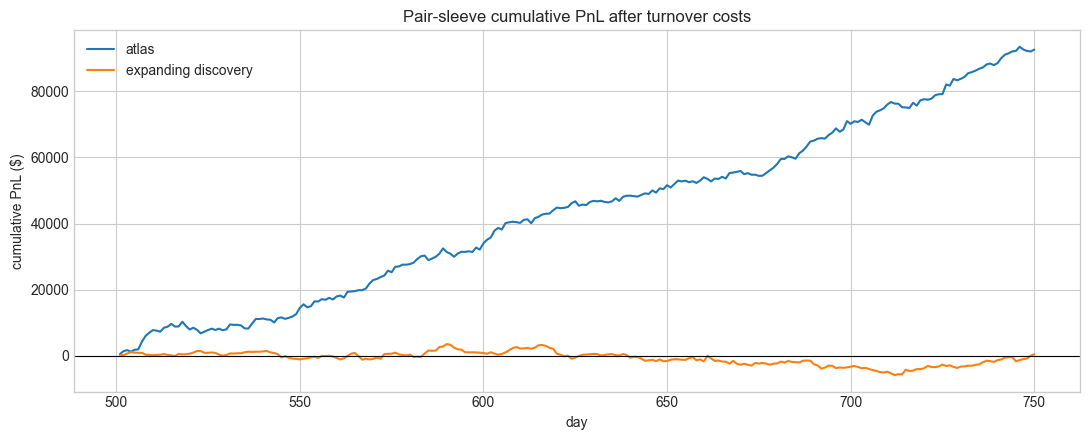

In [10]:
def hac_t_mean(values, lags=5):
    x = np.asarray(values, float)
    centered = x-x.mean()
    n = len(x)
    long_var = centered@centered/n
    for lag in range(1, min(lags, n-1)+1):
        gamma = centered[lag:]@centered[:-lag]/n
        long_var += 2*(1-lag/(lags+1))*gamma
    return float(x.mean()/np.sqrt(max(long_var/n, 1e-18)))

def sleeve_series(kind, start=500, end=750):
    previous = np.zeros(prices.shape[0], dtype=int)
    pnl, gross, approx = [], [], []
    for t in range(start, end):
        lp = logp[:, :t]
        atlas = strategy._atlas_dollars(lp)
        if kind == 'atlas':
            dollars = np.clip(atlas, -strategy.LEG, strategy.LEG)
        elif kind == 'discovery':
            base = atlas + strategy._ridge_dollars(np.diff(lp, axis=1), atlas)
            base[1:] = np.clip(base[1:], -strategy.LEG, strategy.LEG)
            dollars = strategy._expanding_pair_dollars(lp, base)
        else:
            raise ValueError(kind)
        shares = (dollars/prices[:, t-1]).astype(int)
        traded = np.abs(shares-previous)*prices[:, t-1]
        fee = .0001*traded.sum()
        exact = shares@(prices[:, t]-prices[:, t-1]) - fee
        log_approx = dollars@np.diff(logp[:, t-1:t+1], axis=1)[:,0] - fee
        pnl.append(exact); approx.append(log_approx); gross.append(np.abs(dollars).sum())
        previous = shares
    return np.asarray(pnl), np.asarray(gross), np.asarray(approx)

def sleeve_summary(name, pnl, gross, approx):
    curve = np.cumsum(pnl)
    drawdown = curve-np.maximum.accumulate(np.r_[0, curve])[-len(curve):]
    active = gross > 1e-8
    returns = np.divide(pnl, gross, out=np.zeros_like(pnl), where=active)
    market = np.diff(logp[0, 499:750])[:len(pnl)]
    return {
        'sleeve': name, 'days_active': int(active.sum()), 'mean_daily_pnl': pnl.mean(),
        'pnl_std': pnl.std(), 'annualised_sharpe': np.sqrt(250)*pnl.mean()/max(pnl.std(),1e-12),
        'HAC_t_mean': hac_t_mean(pnl), 'cumulative_pnl': pnl.sum(),
        'hit_rate': np.mean(pnl>0), 'max_drawdown': drawdown.min(),
        'mean_gross_active': gross[active].mean() if active.any() else 0,
        'ALGO_beta_gross_return': slope(returns, market),
        'log_PnL_RMSE': np.sqrt(np.mean((pnl-approx)**2)),
    }

atlas_pnl, atlas_gross, atlas_approx = sleeve_series('atlas')
disc_pnl, disc_gross, disc_approx = sleeve_series('discovery')
sleeve_table = pd.DataFrame([
    sleeve_summary('atlas', atlas_pnl, atlas_gross, atlas_approx),
    sleeve_summary('expanding discovery', disc_pnl, disc_gross, disc_approx),
])
display(sleeve_table.round(4))
fig, ax = plt.subplots(figsize=(11, 4.5))
ax.plot(np.arange(501,751), np.cumsum(atlas_pnl), label='atlas')
ax.plot(np.arange(501,751), np.cumsum(disc_pnl), label='expanding discovery')
ax.axhline(0, color='black', lw=.8)
ax.set(title='Pair-sleeve cumulative PnL after turnover costs', xlabel='day', ylabel='cumulative PnL ($)')
ax.legend()
fig.tight_layout()
fig.savefig(OUT / 'pair_sleeve_attribution.png', dpi=160, bbox_inches='tight')
plt.show()
sleeve_table.to_csv(OUT / 'pair_sleeve_attribution.csv', index=False)
atlas_metrics.to_csv(OUT / 'atlas_relationship_metrics.csv', index=False)
pair_table.to_csv(OUT / 'example_pair_metrics.csv', index=False)

## Interpretation rules

1. Near-zero OLS residual mean and residual–regressor dot product prove the fitted-line geometry, but not tradability.
2. Small Engle–Granger p-values and finite half-lives are sample evidence for mean reversion; instability between days 1–500 and 501–750 weakens that evidence.
3. Positive causal forward spread outcomes test the trading direction without using future observations in the fit.
4. A low residual ALGO beta establishes factor neutrality only with respect to that measured factor and sample.
5. HAC t-statistics and drawdowns describe the realised sleeves. No finite historical sample is a mathematical proof of future profit.

## Data-specific conclusion

- **The equation sheet is meaningful as a framework, after correcting its units.** Since `teamName.py` fits log prices, the spread beta maps dollar exposures; shares require the additional price ratio. Kalman innovation must be divided by $\sqrt{S_t}$ and market beta must be fitted on returns.
- **The atlas is supported, but not uniformly permanent.** All 13 atlas pairs have train Engle–Granger p-values below 5%, while only 7/13 do in the held-out refit. Median absolute hedge-beta change is 9.6%, and the searched-break plots show material line shifts.
- **The named SMAH–NGTE example is not supported as a stable trade.** Its train p-value is 0.802, beta changes by 215%, and causal fading loses 67 bps over five days and 309 bps over twenty days on average. By contrast SMAH–ILVX and EORC–NGTE earn approximately 460 and 388 bps over five days with 80% and 77% win rates.
- **Atlas sleeve evidence is strong in days 501–750.** After turnover cost it earns $92,596, averages $370/day, has HAC t=8.16, maximum drawdown of about $3,506, and gross-normalised ALGO beta of -0.009.
- **The current expanding discovery sleeve is not statistically supported at `PAIR_SCALE=1`.** It is active 248/250 days but earns only $509 total, with $455 daily volatility, HAC t=0.071, maximum drawdown about $9,396, and ALGO beta 0.090. Scaling changes dollars at risk, not the absent signal-to-noise evidence.

Therefore the mathematics strongly supports retaining and monitoring the secure atlas relationships, but it does not support treating every expanding two-sigma residual as proven cointegration or allocating it a full pair-scale risk budget.